# Assignment 2: Stationarity tests

**Goal:** test store `CA_1` daily sales with ADF (null: unit root) and KPSS (null: stationary), then difference and retest.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss

plt.style.use("seaborn-v0_8-whitegrid")

search_roots = [Path.cwd(), *Path.cwd().parents]
DATA_DIR = next(
    (root / "m5-forecasting-accuracy" for root in search_roots
     if (root / "m5-forecasting-accuracy").is_dir()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find m5-forecasting-accuracy. Run from the workspace or its notebooks folder."
    )

SALES_PATH = DATA_DIR / "sales_train_validation.csv"
CALENDAR_PATH = DATA_DIR / "calendar.csv"
STORE_ID = "CA_1"
SEASONAL_LAG = 7
print(f"Data folder: {DATA_DIR}")

Data folder: c:\Users\mandabhushan\OneDrive - Nagarro\Documents\D\Learnings\Projects\Time_series\m5-forecasting-accuracy


## Prepare daily series

In [2]:
header = pd.read_csv(SALES_PATH, nrows=0).columns.tolist()
day_cols = [column for column in header if column.startswith("d_")]
if not day_cols:
    raise ValueError("No daily sales columns beginning with 'd_' were found.")

store_totals = None
for chunk in pd.read_csv(SALES_PATH, usecols=["store_id"] + day_cols, chunksize=512):
    store_rows = chunk.loc[chunk["store_id"] == STORE_ID, day_cols]
    if not store_rows.empty:
        chunk_totals = store_rows.sum(axis=0)
        store_totals = chunk_totals if store_totals is None else store_totals.add(chunk_totals)

if store_totals is None:
    raise ValueError(f"Store {STORE_ID!r} was not found in the sales file.")

calendar = pd.read_csv(CALENDAR_PATH, usecols=["d", "date"])
calendar["date"] = pd.to_datetime(calendar["date"])
sales = pd.DataFrame({"d": day_cols, "sales": store_totals.reindex(day_cols).to_numpy()})
sales = sales.merge(calendar, on="d", how="left", validate="one_to_one")
sales = sales.sort_values("date").set_index("date")
if sales.index.hasnans or sales["sales"].isna().any():
    raise ValueError("Sales contain missing dates or values after joining to the calendar.")
if not sales.index.is_unique or not sales.index.to_series().diff().dropna().eq(pd.Timedelta(days=1)).all():
    raise ValueError("Expected one consecutive daily observation per date.")

y = sales["sales"].astype(float).rename("sales")
print(f"Store {STORE_ID}: {y.index.min().date()} through {y.index.max().date()}, {len(y):,} daily observations")
display(y.describe().to_frame("daily unit sales"))

Store CA_1: 2011-01-29 through 2016-04-24, 1,913 daily observations


,daily unit sales
count,1913.000000
mean,4024.158913
std,991.847206
min,0.000000
25%,3349.000000
50%,3902.000000
75%,4633.000000
max,6948.000000


## ADF and KPSS helper

In [3]:
def stationarity_tests(values: pd.Series, label: str) -> dict:
    clean = values.dropna().astype(float)
    if clean.empty or not clean.index.is_monotonic_increasing:
        raise ValueError(f"{label}: expected non-empty, chronologically ordered observations.")
    adf_stat, adf_p, adf_lags, adf_n, _, _ = adfuller(clean, regression="c", autolag="AIC")
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        kpss_stat, kpss_p, kpss_lags, _ = kpss(clean, regression="c", nlags="auto")
    warning_text = "; ".join(str(item.message) for item in caught)
    return {
        "series": label,
        "n": len(clean),
        "ADF statistic": adf_stat,
        "ADF p-value": adf_p,
        "ADF lags": adf_lags,
        "ADF decision (5%)": "reject unit-root null" if adf_p < 0.05 else "do not reject unit-root null",
        "KPSS statistic": kpss_stat,
        "KPSS p-value": kpss_p,
        "KPSS lags": kpss_lags,
        "KPSS decision (5%)": "reject stationary null" if kpss_p < 0.05 else "do not reject stationary null",
        "KPSS warning": warning_text,
    }

transformations = {
    "level": y,
    "first difference (lag 1)": y.diff(),
    "weekly seasonal difference (lag 7)": y.diff(SEASONAL_LAG),
    "first + weekly seasonal differences": y.diff().diff(SEASONAL_LAG),
}
test_results = pd.DataFrame(
    [stationarity_tests(values, label) for label, values in transformations.items()]
).set_index("series")
display(test_results)

C:\Users\mandabhushan\AppData\Local\Temp\ipykernel_26620\230048237.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, adf_n, _, _ = adfuller(clean, regression="c", autolag="AIC")
C:\Users\mandabhushan\AppData\Local\Temp\ipykernel_26620\230048237.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, adf_n, _, _ = adfulle

,n,ADF statistic,ADF p-value,ADF lags,ADF decision (5%),KPSS statistic,KPSS p-value,KPSS lags,KPSS decision (5%),KPSS warning
series,,,,,,,,,,
level,1913,-2.035408,0.271267,26,do not reject unit-root null,13.454732,0.01,7,reject stationary null,The test statistic is outside of the range of ...
first difference (lag 1),1912,-20.626012,0.000000,26,reject unit-root null,0.026208,0.10,52,do not reject stationary null,The test statistic is outside of the range of ...
weekly seasonal difference (lag 7),1906,-19.400488,0.000000,23,reject unit-root null,0.008094,0.10,13,do not reject stationary null,The test statistic is outside of the range of ...
first + weekly seasonal differences,1905,-19.739548,0.000000,25,reject unit-root null,0.020748,0.10,33,do not reject stationary null,The test statistic is outside of the range of ...


## Transformations

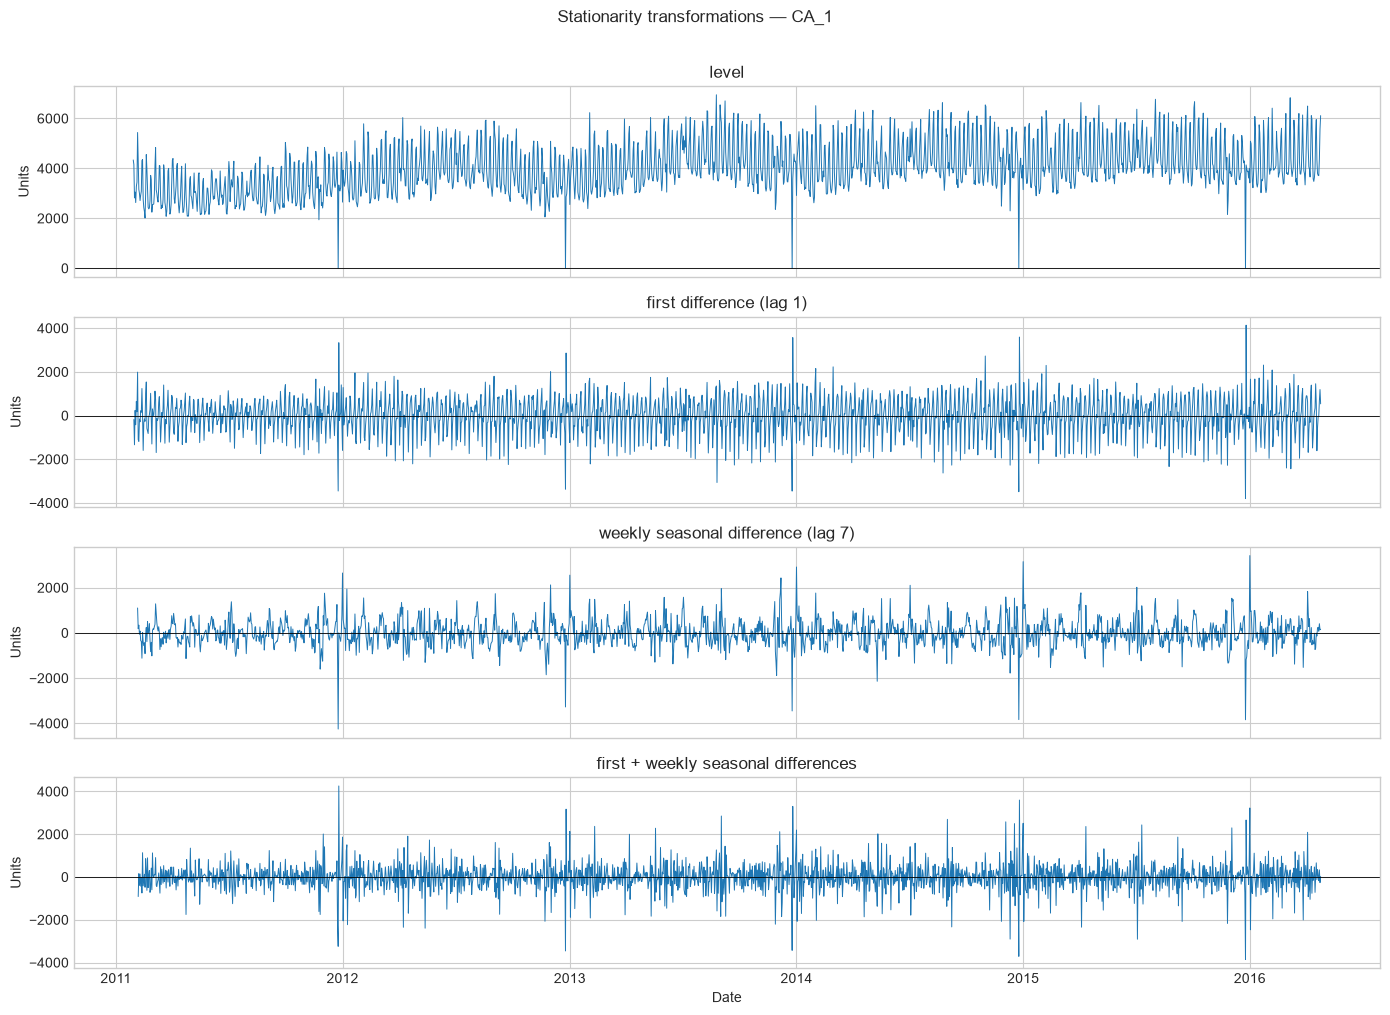

Both first differencing and weekly seasonal differencing produce stationary-looking series under the ADF and KPSS tests; the model specification determines which transformation is used.


In [4]:
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for ax, (label, values) in zip(axes, transformations.items()):
    ax.plot(values.index, values, linewidth=0.7)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set_title(label)
    ax.set_ylabel("Units")
axes[-1].set_xlabel("Date")
fig.suptitle(f"Stationarity transformations — {STORE_ID}", y=1.01)
plt.tight_layout()
plt.show()

print("Both first differencing and weekly seasonal differencing produce stationary-looking series under the ADF and KPSS tests; the model specification determines which transformation is used.")

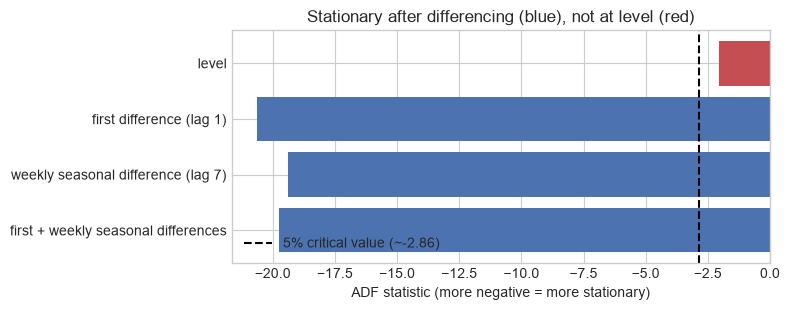

In [5]:
tr = test_results["ADF statistic"]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(tr.index[::-1], tr.values[::-1], color=["#4c72b0" if v < -2.86 else "#c44e52" for v in tr.values[::-1]])
ax.axvline(-2.86, color="black", linestyle="--", label="5% critical value (~-2.86)")
ax.set(xlabel="ADF statistic (more negative = more stationary)", title="Stationary after differencing (blue), not at level (red)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()


## Conclusion

- The level series is **non-stationary** (ADF p = 0.27; KPSS rejects at 5%).
- First, weekly (lag 7) and combined differences are **stationary** under both tests.
- Weekly differencing is the natural choice for this strongly weekly series; tests support, not prove, stationarity.